[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jordy-Castillo/FC_Jordy-Castillo-Trabajos/blob/main/Taller06/FC_Taller06_JordyCastillo.ipynb)

# **FISICA COMPUTACIONAL - TALLER #6**
* **Tema:** Funciones, Variables Globales y Locales, y Módulos
* **Lenguaje:** Fortran & Python
* **Estudiante:** Jordy Castillo Jordán
* **Fecha:** 29/10/2026



In [1]:
!which gfortran > /dev/null || (apt-get -qq update && apt-get -qq install -y gfortran > /dev/null)
!gfortran --version | head -1
!mkdir -p taller_nucleo_atomico

GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0




---
# **PARTE A:**

**Contexto físico.** La masa de un núcleo con $Z$ protones y $A$ nucleones es menor que la suma de las masas de sus componentes: la diferencia es la energía de enlace. En el modelo de la gota líquida (Bethe y Weizsäcker), la energía de enlace **por nucleón** es la suma de cuatro términos:

$$E_B(Z,A) = \underbrace{-\,a_V}_{\text{volumen}} \; + \; \underbrace{a_S\,A^{-1/3}}_{\text{superficie}} \; + \; \underbrace{a_C\,Z^2A^{-4/3}}_{\text{Coulomb}} \; + \; \underbrace{a_A\,\frac{(Z - A/2)^2}{A^2}}_{\text{asimetría}}$$

donde $Z$ es el número de protones, $A$ el número de nucleones (protones más neutrones) y $N = A - Z$ el número de neutrones. Cada término tiene un origen físico:

| Término | Expresión | Origen físico | Efecto |
|---|---|---|---|
| Volumen | $-a_V$ | La fuerza nuclear fuerte es de corto alcance: cada nucleón solo interactúa con sus vecinos inmediatos, así que el enlace es proporcional al número de nucleones y **por nucleón es constante**. | Liga ($<0$) |
| Superficie | $a_S\,A^{-1/3}$ | Los nucleones de la superficie tienen menos vecinos. El núcleo es una esfera de radio $R \propto A^{1/3}$; su superficie es $\propto A^{2/3}$ y, dividida entre $A$, da $A^{-1/3}$. | Resta enlace; pesa más en núcleos livianos |
| Coulomb | $a_C\,Z^2A^{-4/3}$ | Repulsión electrostática entre los $Z$ protones, repartidos en la esfera de radio $R \propto A^{1/3}$: la energía total es $\propto Z^2/A^{1/3}$ y, dividida entre $A$, da $Z^2A^{-4/3}$. | Resta enlace; pesa más en núcleos pesados |
| Asimetría | $a_A\,(Z - A/2)^2/A^2$ | Por el principio de exclusión de Pauli, protones y neutrones ocupan niveles de energía separados: este término por sí solo favorece $Z = N = A/2$, y cualquier exceso de uno de los dos cuesta energía. El mínimo del modelo completo depende también de los otros términos. | Resta enlace si $Z \neq A/2$ |

y la masa atómica aproximada se calcula mediante

$$M(Z,A) = Z\,M_H + (A - Z)\,M_n + A\,E_B(Z,A),$$

donde $Z\,M_H$ es la masa de $Z$ átomos de hidrógeno (cada uno, un protón y un electrón), $(A - Z)\,M_n$ la masa de los $N$ neutrones libres, y $A\,E_B$ la energía de enlace **total**, que es negativa y reduce la masa respecto de los componentes separados. Como se utiliza $M_H$, el resultado incluye la masa de los $Z$ electrones: corresponde aproximadamente a una **masa atómica**, despreciando sus energías de enlace electrónicas.

En las ecuaciones se adopta $c=1$: los símbolos de masa representan su energía equivalente $Mc^2$, expresada en **MeV**. Para expresar la masa como tal, la unidad correspondiente es MeV/$c^2$.

Con esta convención, $E_B < 0$ para un núcleo ligado: cuanto más negativo, más ligado. Las tablas experimentales suelen dar la energía de enlace por nucleón con signo positivo, $B/A = -E_B$.

**Constantes** (O. Zubairi y F. Weber, *Introduction to Computational Physics for Undergraduates*, 2.ª ed., IOP, 2024, problema 7.2):

| $a_V$ | $a_S$ | $a_C$ | $a_A$ | $M_n$ | $M_H$ |
|---|---|---|---|---|---|
| 15.8 MeV | 18.3 MeV | 0.71 MeV | 92.7 MeV | 939.57 MeV | 938.78 MeV |
| coeficiente de volumen | coeficiente de superficie | coeficiente de Coulomb | coeficiente de asimetría | masa del neutrón | masa del átomo de hidrógeno |

Los cuatro coeficientes no se deducen de una teoría: se ajustan a las masas medidas de muchos núcleos. Por eso el modelo se llama *semiempírico*.

Para un $A$ fijo, se busca el núcleo de menor $E_B(Z,A)$ entre $Z = 1, 2, \dots, A$. En todo el taller, «más ligado» se refiere a mayor enlace **por nucleón**, es decir, a un $E_B$ más negativo.

**Alcance físico de la búsqueda.** Minimizar $E_B$ a $A$ fijo no equivale exactamente a minimizar $M$, porque $M_H$ y $M_n$ son diferentes. La estabilidad frente a transformaciones beta requiere comparar las masas de los isóbaros y considerar los canales de decaimiento. En este taller se conserva únicamente la búsqueda del máximo enlace: **no debe cambiarse el criterio de búsqueda por una minimización de la masa**. Para mantener los nombres de archivo y la arquitectura común, se conservan `valle.dat` y el procedimiento `Z_estable`, entendido aquí como el $Z$ de máximo enlace según el modelo.



---
# **PARTE B:**


### **B.1** Diseño: pseudocódigo marco


```
MÓDULO del modelo
    constantes: a_V, a_S, a_C, a_A, M_n, M_H
    funciones de los cuatro términos               (entradas: Z y/o A; salida: el término [MeV])
    función E_B(Z, A)                              (usa las cuatro funciones anteriores)
    función M(Z, A)                                (usa E_B)
    procedimiento Z_estable                        (entrada: A; resultados: el Z de máximo enlace y su E_B)

        (¿cómo se encuentra el Z de menor E_B?)
        Dado un A:
        Iniciar con Z_optimo = 1 y EB_min = E_B(1, A)
        Desde un Z = 2 hasta A hacer:
              Calcular EB_actual = E_B(Z, A)
              Si EB_actual < EB_min entonces:
                   EB_min = EB_actual
                   Z_optimo = Z
              Fin Si
        Fin Desde
        Devolver Z_optimo y EB_min                  (salidas; Z_optimo; EB_min)


        [¿por qué se usa una subrutina para entregar los dos resultados separados]
        Se usa una subrutina ya que estas se utilizan cuando un procedimiento tiene como salidas dos o mas resultados
        independientes (en este caso el procedimiento Z_estable.
        Este recibe de entrada A, pero deja como resultado Z_optimo y EB_min

PROGRAMA PRINCIPAL (usa el módulo)
    para cada uno de los 8 núcleos, en el orden del enunciado:
        escribir una fila de nucleos.dat: Z, A, los cuatro términos, E_B y M
    para A = 4, 5, ..., 260:
        obtener el Z de máximo enlace y su E_B con Z_estable
        escribir una fila de valle.dat: A, Z, E_B

        se comienza con A=4
        [¿cómo se identifica, durante este ciclo, el núcleo más ?]
        Si EB_min < EB_global_min entonces:
              EB_global_min = EB_min
              A_max = A
              Z_max = Z_encontrado
        Fin Si

  
    escribir el núcleo más ligado en maximo.dat
```

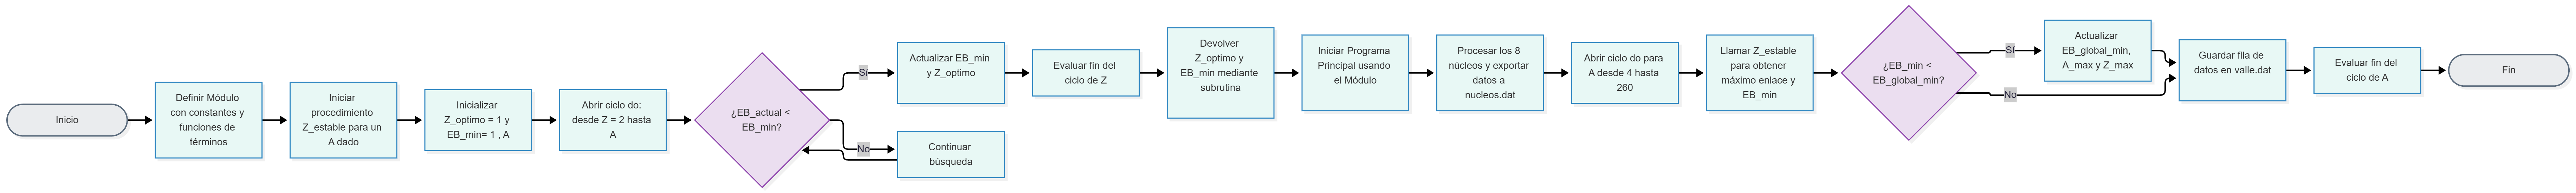

In [3]:
#ELABORACION MEDIANTE MERMAID
from IPython.display import Image
Image(filename="/content/T6_DiagramaB.png")


### **B.2** ¿Que debe preparar?

La parte B consiste en **dos archivos de Fortran**, que se escriben en las dos celdas de la sección B.3, que ya empiezan con la línea `%%writefile` y el nombre del archivo. La tercera celda, ya escrita, los compila y ejecuta; no la modifique.

| Archivo | Qué contiene | Requisitos |
|---|---|---|
| `taller_nucleo_atomico/modulo_nucleo.f90` | El **módulo** del modelo: <br>• las seis constantes de la tabla del enunciado; <br>• una función para cada uno de los cuatro términos; <br>• una función para $E_B(Z,A)$, que use las cuatro anteriores; <br>• una función para $M(Z,A)$; <br>• el procedimiento que, dado $A$, entrega el $Z$ de máximo enlace y su $E_B$. | R2 a R7 |
| `taller_nucleo_atomico/programa_nucleo.f90` | El **programa principal**: usa el módulo y escribe los tres archivos de resultados. Si necesita procedimientos propios (por ejemplo, para escribir una fila), van después de su `contains`. | R2, R6, R7 |

**Resultados de la parte B**, que escribe el programa al ejecutarse, en la misma carpeta y con el formato de la tabla de la sección A: `nucleos.dat`, `valle.dat` y `maximo.dat`.

**La parte B está terminada cuando** la celda de compilación se ejecuta sin errores, los tres archivos existen y la primera fila de `nucleos.dat` (el ${}^{244}$Pu) tiene $E_B \approx -7.5361$ MeV. Esto es un control inicial; la validación completa se realiza en D.

### **B.3** Codigo en Fortran

In [ ]:
%%writefile taller_nucleo_atomico/modulo_nucleo.f90
!!!!!!!!!! Módulo de la fórmula semiempírica !!!!!!!!!!


!!! DECLARAMOS LAS CONSTANTES !!!

module modulo_nucleo
  implicit none
  integer, parameter :: dp = kind(1.0d0)      !doble precisión
  real(dp), parameter :: a_V = 15.8_dp        !coeficiente de volumen
  real(dp), parameter :: a_S = 18.3_dp        !coeficiente de superficie
  real(dp), parameter :: a_C = 0.71_dp        !coeficiente de Coulomb
  real(dp), parameter :: a_A = 92.7_dp        !Coeficiente de asimetria
  real(dp), parameter :: M_n = 939.57_dp      !masa del neutrón
  real(dp), parameter :: M_H = 938.78_dp      !masa del atomo de hidrogeno (H)


!!! DECLARAMOS LAS 4 FUNCIONES DE LOS TERMINOS INDIVIDUALES !!!

contains

  !!! Función del Volumen !!!
  real(dp) function termino_vol(a)
    implicit none
    integer, intent(in) :: a
    termino_vol = -a_V + real(0*a, dp)          !Evita la advertencia de variable no usada (fallo continuo que tuve)
  end function termino_vol

  !!! Función de la Superficie !!!
  real(dp) function termino_sup(a)
    implicit none
    integer, intent(in) :: a
    termino_sup = a_S * (real(a, dp)**(-1.0_dp/3.0_dp))
  end function termino_sup

  !!! Función del Coulomb !!!
  real(dp) function termino_coul(z, a)
    implicit none
    integer, intent(in) :: z, a
    termino_coul = a_C * (real(z, dp)**2.0_dp) * (real(a, dp)**(-4.0_dp/3.0_dp))
  end function termino_coul

  !!! Función de la Asimetria !!!
  real(dp) function termino_asim(z, a)
    implicit none
    integer, intent(in) :: z, a
    termino_asim = (a_A * ((real(z, dp) - real(a, dp)/2.0_dp)**2.0_dp) / real(a, dp)**2.0_dp)
  end function termino_asim


!!! DECLARAMOS LA FUNCION QUE SUMA LOS 4 TERMINOS !!!

  real(dp) function E_B(z, a)
    implicit none
    integer, intent(in) :: z, a
    E_B = termino_vol(a) + termino_sup(a) + termino_coul(z, a) + termino_asim(z, a)
  end function E_B

!!! DECLARAMOS LA FUNCIÓN QUE EVALUA LA MASA ATOMICA !!!

  real(dp) function M_masa(z, a)
    implicit none
    integer, intent(in) :: z, a
    M_masa = real(z, dp) * M_H + (real(a, dp) - real(z, dp))*M_n + real(a, dp)*E_B(z, a)
  end function M_masa

!! CREAMOS UNA SUBRUTINA PARA ENCONTRAR EL Z DE MENOR E_B !!!

  subroutine z_estable(a, z_optimo, EB_min)
    implicit none
    integer, intent(in) :: a                     !variable de entrada
    integer, intent(out) :: z_optimo             !variable de salida
    real(dp), intent(out) :: EB_min              !variable de salida

    integer :: z                                 !variable local
    real(dp) :: EB_actual                        !variable local
    z_optimo = 1                                 !iniciar con un valor arbitrario
    EB_min = E_B(1, a)                           !iniciar con un valor arbitrario

    do z = 2, a                                  !creamos un ciclo en Z = 2,3,4... A
      EB_actual = E_B(z, a)
      if (EB_actual < EB_min) then               !si EB_actual es menor que EB_min entonces;
        EB_min = EB_actual                       !actualizamos el EB_min
        z_optimo = z                             !actualizamos el Z_optimo
      endif
    end do
  end subroutine z_estable

  end module modulo_nucleo

In [ ]:
%%writefile taller_nucleo_atomico/programa_nucleo.f90
!!!!!!!!!! Programa principal !!!!!!!!!!

!!! DECLARAMOS EL PROGRAMA Y LAS VARIABLES !!!

program programa_nucleo
  use modulo_nucleo, only: dp, termino_vol, termino_sup, termino_coul, termino_asim, E_B, M_masa, z_estable
  implicit none

  integer :: a                                            !contador
  integer :: u_nuc, u_valle, u_max                         !unidades logicas de los archivos a usar
  integer :: z_opt, a_global_max, z_global_max             !resultados de la funcion z_estable
  real(dp) :: EB_opt, EB_global_min                        !minimos de la energia de enlace


!!! DEFINIMOS LOS 8 NUCLIDOS DE REFERENCIA EN LISTAS !!!
!! El orden dado es Pu, Ge, Hf, Ar, Fe, Ca, 235U, 238U

open(newunit=u_nuc, file='nucleos.dat', status='replace', action='write')

!Llamadas a la subrutina auxiliar para los 8 núclidos de referencia (no se pueden usar arreglos)
!La subrutina la pondremos al final para mayor comodidad

call escribir_nucleo(94, 244) ! Pu-244
call escribir_nucleo(32, 70)  ! Ge-70
call escribir_nucleo(72, 179) ! Hf-179
call escribir_nucleo(18, 38)  ! Ar-38
call escribir_nucleo(26, 56)  ! Fe-56
call escribir_nucleo(20, 40)  ! Ca-40
call escribir_nucleo(92, 235) ! U-235
call escribir_nucleo(92, 238) ! U-238
close(u_nuc)


!!! GENERACIÓN DE EL ARCHIVO "VALLE.DAT" !!!
open(newunit=u_valle, file='valle.dat', status='replace', action='write')

!! escribimos la fila de valle.dat !!
EB_global_min = huge(1.0_dp)
 do a = 4, 260
   call z_estable(a, z_opt, EB_opt)                              !llamamos la subrutina para obtener z_opt y EB_opt
   write(u_valle, "(2I6, F18.8)") a, z_opt, EB_opt               !escribimos la fila de valle.dat

   if (EB_opt < EB_global_min) then                              !si EB_opt es menor que EB_global_min entonces se cumple;
     EB_global_min = EB_opt
     a_global_max = a
     z_global_max = z_opt
   endif
 end do
close (u_valle)

!!! GENERACIÓN DE EL ARCHIVO "MAXIMO.DAT" !!!
open(newunit=u_max, file='maximo.dat', status='replace', action='write')

!! escribimos la fila de maximo.dat !!
  write(u_max, "(2I6, F18.8)") a_global_max, z_global_max, EB_global_min
close(u_max)

!!CREAMOS OTRA SUBRUTINA PARA ESCRIBIR LOS NUCLEOS
!!Subrutina auxiliar para escribir un solo núcleo en nucleos.dat!!

contains
  subroutine escribir_nucleo(z_val, a_val)
    implicit none
    integer, intent(in) :: z_val, a_val

    write(u_nuc, '(2I6, 5F18.8, F18.4)') &
      z_val, a_val, termino_vol(a_val), termino_sup(a_val), &
      termino_coul(z_val, a_val), termino_asim(z_val, a_val), &
      E_B(z_val, a_val), M_masa(z_val, a_val)
  end subroutine escribir_nucleo

end program programa_nucleo

In [ ]:
# Compilación y ejecución (NO MODIFICAR): primero el módulo, después el programa.
# Se ejecuta dentro de taller_nucleo_atomico/ para que los .dat queden allí.
!cd taller_nucleo_atomico && gfortran -Wall -Wextra modulo_nucleo.f90 programa_nucleo.f90 -o nucleo && ./nucleo



---
# **PARTE C:**

### **C.1** ¿Que debe preparar?
La parte C consiste en **un módulo de Python** y **una celda que lo usa**. Trabaja solo con los archivos que escribió la parte B: no vuelve a calcular la fórmula.

| Dónde | Qué contiene | Requisitos |
|---|---|---|
| `taller_nucleo_atomico/analisis_nucleo.py` (celda C.3) | Cuatro funciones, cada una con su docstring de entradas y salidas: <br>• una que lea `valle.dat` y devuelva sus tres columnas; <br>• una que encuentre el núcleo más ligado por nucleón recorriendo los datos con un ciclo y un condicional, como en Fortran (sin `min`, `np.min` ni `np.argmin`); <br>• una que escriba ese núcleo en `maximo_python.dat`, con el formato de `maximo.dat`; <br>• una que haga la gráfica de $B/A = -E_B$ contra $A$ con los puntos experimentales de la celda C.2 y la guarde como imagen. | P1 a P3 |
| Celda de uso (C.4) | Importa el módulo (las primeras líneas ya están escritas), llama a las cuatro funciones e imprime el núcleo más ligado. | — |

**Resultados de la parte C**: `taller_nucleo_atomico/maximo_python.dat` y `taller_nucleo_atomico/curva_enlace.png`.

**La parte C está terminada cuando** Python imprime el mismo $A$ y $Z$ que `maximo.dat` y la gráfica muestra la curva del modelo con los diez puntos experimentales.

### **C.2** Datos experimentales
Valores de la energía de enlace por nucleón, $B/A = -E_B$, en MeV (evaluación de masas atómicas AME2020). Use esta celda tal como está. Los puntos representan los núclidos indicados; la curva representa el máximo enlace para cada $A$ según el modelo. No son necesariamente el mismo $Z$, por lo que la comparación gráfica es orientativa. Para una comparación numérica de un núclido concreto, use su mismo $Z$ y $A$.

In [ ]:
# Datos experimentales: (símbolo, Z, A, B/A [MeV]) -- AME2020
EXPERIMENTALES = [
    ("He-4",    2,   4, 7.0739),
    ("C-12",    6,  12, 7.6801),
    ("O-16",    8,  16, 7.9762),
    ("Ca-40",  20,  40, 8.5513),
    ("Fe-56",  26,  56, 8.7903),
    ("Ni-62",  28,  62, 8.7945),
    ("Sn-120", 50, 120, 8.5045),
    ("Pb-208", 82, 208, 7.8675),
    ("U-235",  92, 235, 7.5909),
    ("U-238",  92, 238, 7.5701),
]

### **C.3** Modulo de Python

In [ ]:
%%writefile taller_nucleo_atomico/analisis_nucleo.py
########### Módulo de análisis ###########

import numpy as np
import matplotlib.pyplot as plt

#Leeremos el archivo de Fortran valle.dat para tener como salidas los arreglos de
#los numeros de masa A, numeros atomicos de maximo alcance Z, y energiar de enlace EB
#y asi poder utilizarlos en este lenguaj de python

def leer_valle(archivo):
  """
  Lee el archivo de datos valle.dat

  ENTRADA: un archivo (str)

  SALIDA: tupla de arreglos (a,z,EB)
          a: numeros de masa
          z: numeros atomicos
          EB: energia de enlace por nucleon

  """
  datos = np.loadtxt(archivo)
  a = datos[:,0]
  z = datos[:,1]
  EB = datos[:,2]
  return a, z, EB


#encontramos el nucleo con mayor enlace por nucleon, es decir, el maximo alcance es
#el valor mas negativo de E_B, como se habia definido anteriormente

def encontrar_maximo(a,z,EB):
  """
  Encuentra el nucleo con mayor enlace por nucleon de toda la curva a construir

  ENTRADA: arreglos (a, z, EB)
          a: numeros de masa
          z: numeros atomicos
          EB: energia de enlace por nucleon

  SALIDA: tupla (a_max, z_max, EB_min)
          son valores correspondientes al nucleo mas ligado

  """
  a_min = a[0]
  z_min = z[0]
  EB_min = EB[0]

  for i in range(len(EB)):
    if EB[i] < EB_min:
      a_min = a[i]
      z_min = z[i]
      EB_min = EB[i]

  return a_min, z_min, EB_min


#escribimos el nucleo mas ligado encontrado por la funcion anterior

def escribir_maximo_python(archivo_salida="maximo_python.dat", archivo_valle="valle.dat"):
  """
  Escribe el nucleo mas ligado encontrado por python en un archivo

  ENTRADA:
          a_max: numeros de masa A del minimo global
          z_max: numero atomico Z del minimo global
          EB_max: energia de enlace minima (MeV)
          archivo: ruta de destino maximo_python.dat

  SALIDA: ninguna, ya que genera un archivo de texto estilo fotran

  """

  A, Z, EB = leer_valle(archivo_valle)
  a_max, z_max, eb_max = encontrar_maximo(A, Z, EB)

  with open(archivo_salida, "w") as f:                                #abrimos el archivo de salida en modo escritura (mismo formato usado en fortran)
    f.write(f"{int(a_max):6d}{int(z_max):6d}{eb_max:18.8f}\n")


#generamos y guardamos la grafica de B/A = -EB vs A, con los puntos experimentales dados para esta parte

def graficar_curva(archivo_valle="valle.dat", experimental_data=None, imagen_salida="curva_enlace.png"):
  """
  Genera y guarda la grafica de B/A = -EB vs A con los puntos experimentales dados

  ENTRADA:
          a: numeros de masa A del modelo
          EB: energias de enlace de EB del modelo (-Mev)
          datos_exp: lista de tuplas con datos AME2020 (nombre, Z, A, B/A)
          archivo_png: ruta donde se gaurdara la imagen

  SALIDA: ninguna, ya que genera un archivo de texto estilo fotran

  """

  A, Z, EB = leer_valle(archivo_valle)                                        #Leer los datos del modelo
  B_A_modelo = -EB                                                            #Calcular la energía de enlace por nucleón

  AZUL = "#162A54"                                                            #Colores de la gráfica
  ROJO = "#B02A20"

  plt.figure(figsize=(8, 5))                                                  #Dibujar la curva teórica
  plt.plot(A, B_A_modelo, color=AZUL, label="Modelo de Gota Líquida")

  if experimental_data is not None:           #comprueba que existan datos experimentales
        exp_A = []                              #lista para guardar coordenada X
        exp_BA = []                             #lista para guardar corrdenada Y
        exp_labels = []                         #lista para guardar los nombres

        for item in experimental_data:          #Obtener los datos de cada elemento
            exp_labels.append(item[0])          #toma el nombre del elemento y lo pone en la lista de nombres
            exp_A.append(item[2])               #toma el numero de nucleones y lo pone en la lista de nucleones
            exp_BA.append(item[3])              #toma la energia de enlace por nucleon y lo pone en la lista de energias de enlace

        plt.scatter(exp_A, exp_BA, color=ROJO, label="Datos experimentales (AME2020)")   #dibujar los puntos experimentales
                                                                                         #scatter recibe dos listas (NUEVO PARA MI)

        for i in range(len(exp_A)):                                             #escribir el nombre de cada elemento junto a su punto
            y_offset= 6 if i % 2 == 0 else -12                #añadi esto para que los nombres no se sobreponieran, y asi poderlos leer
            plt.annotate(exp_labels[i], (exp_A[i], exp_BA[i]), textcoords="offset points", xytext=(6, y_offset), ha="center", fontsize=8, color=ROJO)
            #escribir el nombre de la posicion i en sus coordenadas. #annotate (NUEVO PARA MI)

  plt.xlabel("Número de nucleones A")
  plt.ylabel("Energía de enlace por nucleón B/A [MeV]")
  plt.title("Valle de Estabilidad y Curva de Enlace Nuclear")
  plt.grid(True)
  plt.legend()
  plt.tight_layout()
  plt.savefig(imagen_salida, dpi=300)
  plt.close()

### **C.4** Uso del Modulo

In [ ]:
########### Uso del módulo de análisis ###########

#Las tres líneas siguientes ya están escritas: agregan la carpeta del Taller a la
#ruta de búsqueda de Python, importan el módulo y lo releen si fue modificado.

import sys, importlib
sys.path.insert(0, "taller_nucleo_atomico")
import analisis_nucleo
_ = importlib.reload(analisis_nucleo)


##############################################################

# primero leemos las columnas de "valle.dat" de fortran
a, z, EB = analisis_nucleo.leer_valle("taller_nucleo_atomico/valle.dat")

# luego, identificamos el minimo global de la curva generada anteriormente
a_max, z_max, EB_max = analisis_nucleo.encontrar_maximo(a, z, EB)

# escribimos el archivo "maximo_python.dat" usando la función correcta definida en el módulo
analisis_nucleo.escribir_maximo_python("taller_nucleo_atomico/maximo_python.dat", "taller_nucleo_atomico/valle.dat")

# generamos la grafica y guardamos en "curva_enlace.png"
analisis_nucleo.graficar_curva("taller_nucleo_atomico/valle.dat", EXPERIMENTALES, "taller_nucleo_atomico/curva_enlace.png")

print(f">>> Mínimo global en Python: A = {int(a_max)}, Z = {int(z_max)}, E_B = {EB_max:.8f} MeV")



---
# **PARTE D:**

La celda siguiente revisa los archivos, sus dimensiones, valores numéricos y coherencia. Los resultados de Fortran deben ser posteriores a sus dos archivos fuente. `maximo_python.dat` debe ser posterior al módulo de análisis y a `valle.dat`. Los cuatro controles informan PASS o FAIL sin detener el notebook. **Esta celda no debe modificarse.**

| Caso | Qué se comprueba |
|---|---|
| 1 | Los ocho núclidos de `nucleos.dat`: orden, cuatro términos, $E_B$ y masa atómica aproximada. |
| 2 | `valle.dat` completo: $A=4,\dots,260$, valores enteros válidos y máximo enlace para cada $A$; incluye la referencia $A=208$, $Z=82$. |
| 3 | Referencia $A=238$, $Z=92$, y coherencia entre el $E_B$ guardado y el modelo en todas las filas de `valle.dat`. |
| 4 | Los máximos de Fortran y Python coinciden con el mínimo global de `valle.dat`; existe una imagen PNG no vacía. |

Las referencias se evalúan en doble precisión con las constantes del enunciado. Por ello pueden diferir en los últimos decimales de una salida publicada con otra precisión. Para ${}^{244}$Pu: $E_B \approx -7.53611738$ MeV y $M \approx 227\,342.0074$ MeV.

**4/4 PASS es necesario, pero no suficiente.** La celda no evalúa la arquitectura del código, el uso de `intent`, la independencia de variables locales, la calidad de la gráfica ni las explicaciones. No consulte su implementación como guía para resolver el algoritmo: utilice los mensajes para localizar qué resultado debe revisar.

In [ ]:
# ===================== VERIFICACIÓN — NO MODIFICAR =====================
from pathlib import Path
import numpy as np

CARPETA = Path("taller_nucleo_atomico")
veredictos = []

def informar(nombre, condicion, detalle=""):
    veredictos.append(bool(condicion))
    print(f"{'PASS' if condicion else 'FAIL'} | {nombre}" + (f" — {detalle}" if detalle else ""))

def leer_salida(nombre, filas, columnas, origen="fortran"):
    ruta = CARPETA / nombre
    if not ruta.is_file():
        raise ValueError(f"falta {ruta}")
    if origen == "fortran":
        fuentes = [CARPETA / "modulo_nucleo.f90", CARPETA / "programa_nucleo.f90"]
    else:
        fuentes = [CARPETA / "analisis_nucleo.py", CARPETA / "valle.dat"]
    for fuente in fuentes:
        if not fuente.is_file():
            raise ValueError(f"falta {fuente}")
        if ruta.stat().st_mtime < fuente.stat().st_mtime:
            raise ValueError(f"{nombre} es anterior a {fuente.name}: vuelva a ejecutar el cálculo correspondiente")
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape != (filas, columnas) or not np.isfinite(datos).all():
        raise ValueError(f"formato incorrecto en {nombre}: se esperaban {filas} filas y {columnas} columnas finitas")
    return datos

# Implementación de referencia exclusiva de la verificación.
def referencia_terminos(z, a):
    z, a = np.asarray(z, dtype=float), np.asarray(a, dtype=float)
    return np.broadcast_arrays(-15.8 + np.zeros_like(a), 18.3*a**(-1.0/3.0),
                               0.71*z**2*a**(-4.0/3.0), 92.7*(z-a/2.0)**2/a**2)

def referencia_enlace(z, a):
    return sum(referencia_terminos(z, a))

def leer_valle():
    datos = leer_salida("valle.dat", 257, 3)
    if not np.array_equal(datos[:, 0], np.arange(4, 261)):
        raise ValueError("valle.dat debe tener A = 4, 5, ..., 260, en ese orden")
    if not np.array_equal(datos[:, 1], np.rint(datos[:, 1])):
        raise ValueError("los valores de Z deben ser enteros")
    if np.any((datos[:, 1] < 1) | (datos[:, 1] > datos[:, 0])):
        raise ValueError("cada fila debe cumplir 1 <= Z <= A")
    return datos

# 1) Ocho núclidos: todos los términos, el enlace y la masa.
try:
    nuc = leer_salida("nucleos.dat", 8, 8)
    orden = np.array([(94,244), (32,70), (72,179), (18,38), (26,56), (20,40), (92,235), (92,238)])
    if not np.array_equal(nuc[:, :2], orden):
        raise ValueError("Z y A deben ser enteros y seguir el orden del enunciado")
    z, a = orden[:, 0], orden[:, 1]
    terminos = np.column_stack(referencia_terminos(z, a))
    eb = terminos.sum(axis=1)
    masa = z*938.78 + (a-z)*939.57 + a*eb
    ok = (np.allclose(nuc[:, 2:6], terminos, rtol=0, atol=1e-7)
          and np.allclose(nuc[:, 6], eb, rtol=0, atol=1e-7)
          and np.allclose(nuc[:, 7], masa, rtol=0, atol=1e-3)
          and np.allclose(nuc[:, 2:6].sum(axis=1), nuc[:, 6], rtol=0, atol=1e-7))
    informar("Caso 1: ocho núclidos", ok, f"Pu-244: E_B = {nuc[0,6]:.8f} MeV; M = {nuc[0,7]:.4f} MeV")
except Exception as error:
    informar("Caso 1: ocho núclidos", False, str(error))

# 2) La búsqueda obtiene el máximo enlace para cada A del intervalo.
try:
    valle = leer_valle()
    correctos = []
    for a, z, eb in valle:
        candidatos = np.arange(1, int(a)+1)
        energias = referencia_enlace(candidatos, a)
        correctos.append(abs(float(referencia_enlace(z, a)) - energias.min()) <= 1e-7)
    fila = valle[valle[:, 0] == 208][0]
    ok = all(correctos) and fila[1] == 82 and abs(fila[2] - (-7.800561449221129)) <= 1e-7
    informar("Caso 2: máximo enlace para cada A", ok, f"{sum(correctos)}/257 búsquedas correctas; A=208: Z={fila[1]:.0f}")
except Exception as error:
    informar("Caso 2: máximo enlace para cada A", False, str(error))

# 3) Energías de todas las filas y referencia de U-238.
try:
    valle = leer_valle()
    esperado = referencia_enlace(valle[:, 1], valle[:, 0])
    fila = valle[valle[:, 0] == 238][0]
    ok = (np.allclose(valle[:, 2], esperado, rtol=0, atol=1e-7)
          and fila[1] == 92 and abs(fila[2] - (-7.579586363043683)) <= 1e-7)
    informar("Caso 3: energías de la curva y U-238", ok, f"A=238: Z={fila[1]:.0f}; E_B={fila[2]:.8f} MeV")
except Exception as error:
    informar("Caso 3: energías de la curva y U-238", False, str(error))

# 4) Mínimo global: dos lenguajes y archivo de imagen.
try:
    valle = leer_valle()
    mf = leer_salida("maximo.dat", 1, 3)[0]
    mp = leer_salida("maximo_python.dat", 1, 3, origen="python")[0]
    referencia = valle[np.argmin(valle[:, 2])]
    def coincide(fila):
        return (np.array_equal(fila[:2], referencia[:2])
                and abs(fila[2]-referencia[2]) <= 1e-7)
    imagen = CARPETA / "curva_enlace.png"
    png_ok = (imagen.is_file() and imagen.stat().st_size > 8
              and imagen.read_bytes()[:8] == b"\x89PNG\r\n\x1a\n")
    ok = (coincide(mf) and coincide(mp)
          and abs(referencia[2] - (-8.69506905766211)) <= 1e-7 and png_ok)
    informar("Caso 4: mínimo global e imagen", ok,
             f"Fortran: A={mf[0]:.0f}, Z={mf[1]:.0f}; Python: A={mp[0]:.0f}, Z={mp[1]:.0f}; PNG: {'presente' if png_ok else 'falta o formato incorrecto'}")
except Exception as error:
    informar("Caso 4: mínimo global e imagen", False, str(error))

print(f"\nResumen: {sum(veredictos)}/4 PASS")
print("La arquitectura, los requisitos y la interpretación se revisan por separado.")




---
# **PARTE E:**
Responda en celdas de texto, debajo de cada pregunta. Use los resultados de su propio programa. Los cálculos adicionales de esta sección pueden realizarse llamando a los procedimientos de sus módulos; **no cambie el modelo de cuatro términos ni los archivos que utiliza la verificación de D**.

1. Usando `nucleos.dat`, elija un núcleo relativamente liviano y otro pesado e identifíquelos. Compare los términos de superficie y Coulomb en ambos casos. ¿Cuál de esos dos términos penaliza más el enlace en cada uno? Explique cómo su competencia contribuye a que la curva $B/A$ presente un máximo.

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
Elegiré el argón-38 ($^{38}\mathrm{Ar}$) como núcleo liviano ($Z=18$, $A=38$) y el plutonio-244 ($^{244}\mathrm{Pu}$) como núcleo pesado ($Z=94$, $A=244$).

Los términos de superficie calculados son $+5.443\ \mathrm{MeV}$ y $+2.929\ \mathrm{MeV}$, respectivamente, redondeados a cuatro cifras significativas. Por su parte, los términos de Coulomb son $+1.801\ \mathrm{MeV}$ y $+4.115\ \mathrm{MeV}$, respectivamente. Estos valores se calcularon utilizando las constantes proporcionadas y las expresiones definidas en la teoría.



**Para el argón-38 ($^{38}\mathrm{Ar}$):**

$$
Superficie =(18.3)A^{-1/3}
=+5.44322840\ \mathrm{MeV}
$$

$$
Coulomb =(0.71)Z^2A^{-4/3}
=+1.80063310\ \mathrm{MeV}
$$

**Para el plutonio-244 ($^{244}\mathrm{Pu}$):**

$$
Superficie =(18.3)A^{-1/3}
=+2.92856239\ \mathrm{MeV}
$$

$$
Coulomb =(0.71)Z^2A^{-4/3}
=+4.11459999\ \mathrm{MeV}
$$

\
Al comparar estos valores, se observa que el término de superficie del $^{38}\mathrm{Ar}$ es considerablemente mayor que el del $^{244}\mathrm{Pu}$. En los núcleos pequeños, una mayor proporción de nucleones se encuentra cerca de la superficie esférica, donde sus interacciones con otros nucleones están menos favorecidas que en el interior. Como consecuencia, el efecto de superficie reduce la energía de enlace total del núcleo.

Por otro lado, el $^{244}\mathrm{Pu}$ presenta un término de Coulomb mayor. En los núcleos pesados, el incremento del número de protones intensifica la repulsión electrostática entre ellos, lo que reduce la energía de enlace y contribuye a disminuir la estabilidad nuclear.

Esta competencia entre ambos efectos contribuye a explicar el comportamiento de la energía de enlace por nucleón, $B/A$. En los núcleos pequeños, el efecto relativo de la superficie es importante; a medida que aumenta el número másico $A$, este efecto pierde importancia relativa. Sin embargo, en los núcleos pesados, la contribución repulsiva de Coulomb aumenta debido a su dependencia con $Z^2$, lo que dificulta mantener una elevada energía de enlace por nucleón.

En conclusión, la competencia entre la disminución del efecto relativo de superficie y el crecimiento de la repulsión de Coulomb contribuye a explicar la existencia de un máximo en la curva de energía de enlace por nucleón para núcleos de masas intermedias.


# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --


2. El modelo predice su mayor enlace por nucleón en un $A$ distinto del ${}^{62}$Ni experimental. Calcule la diferencia de $E_B$ entre el máximo del modelo y el punto de su curva con $A=62$. Exprese también la diferencia como porcentaje de la magnitud de $E_B$ en ese punto. Discuta el tamaño de la diferencia y las limitaciones del modelo que podrían contribuir a ella. Distinga esta comparación entre puntos de la curva de una comparación directa con el núclido experimental: para esta última debe usar $Z=28$, $A=62$.

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
El modelo predice su máximo enlace por nucleón en $A=65$, $Z=29$, con $E_B=-8.69506906\ \text{MeV}$. Segun lo obtenido en maximo.dat.

Para el punto de la curva con $A=62$, $Z=28$, se obtiene $E_B=-8.69089084\ \text{MeV}$. Por tanto, la diferencia entre ambos puntos es:

$$
\Delta E_B = |-8.69506906 - (-8.69089084)|
= 0.00417822\ \text{MeV}
$$

\
Expresada como porcentaje (tambien llamado E.R.P) de la magnitud de la energía de enlace en $A=62$:

$$
\%\Delta E_B =
\frac{0.00417822}{8.69089084}\times 100
\approx 0.0481\%
$$


\
Esta diferencia es muy pequeña, lo que indica que la curva del modelo es bastante plana cerca de su máximo. Sin embargo, el modelo tiene limitaciones, ya que no considera explícitamente los efectos de capas ni el apareamiento entre nucleones, que pueden influir en la estabilidad de núcleos específicos.

Esta comparación corresponde únicamente a dos puntos de la curva teórica, en cambio, al comparar directamente el resultado del modelo para el $^{62}\mathrm{Ni}$ ($Z=28$, $A=62$) con el valor experimental de $B/A=8.7945\ \text{MeV}$, se obtiene una diferencia de $0.10360916\ \text{MeV}$, aproximadamente un $1.18\%$. Esto muestra que, aunque el máximo del modelo y el punto con $A=62$ son muy similares entre sí, por lo cual se puede afirmar que el modelo presenta una diferencia mayor respecto al valor experimental.


# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --


3. Para $A=56$, ¿qué $Z$ tiene el mayor enlace por nucleón en el modelo de cuatro términos? Compárelo con el hierro ($Z=26$): calcule la diferencia de energía **total**, indicando el orden de la resta, y diga cuál resulta más ligado.

   La fórmula completa incluye un quinto término, el de **apareamiento**: protones y neutrones tienden a formar pares. En la energía total, la corrección vale $-a_P A^{-1/2}$ si $Z$ y $N$ son ambos pares, $+a_P A^{-1/2}$ si ambos son impares, y cero si $A$ es impar, con $a_P\approx12$ MeV. Calcule la corrección para los dos núcleos comparados y determine si invierte su orden de enlace. Recuerde que esta corrección es de energía **total**: para sumarla a $E_B$ debe dividirla entre $A$.

   Este es un **cálculo adicional de comparación**: no incorpore el apareamiento a las funciones del modelo base ni regenere con él los archivos de D. Basta comparar los dos candidatos; no se pide repetir la búsqueda global con el modelo ampliado.

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
Para $A=56$, el modelo de cuatro términos predice el mayor enlace por nucleón en $Z=25$, correspondiente al manganeso-56 ($^{56}\mathrm{Mn}$), con $E_B=-8.67953010\ \mathrm{MeV}$. Para el hierro-56 ($Z=26$), se obtiene $E_B=-8.65832033\ \mathrm{MeV}$.

\
Para comparar sus energías totales, multiplicamos la energía por nucleón por $A=56$:

$$
E_{\mathrm{tot}}(25,56)=-486.05368568\ \mathrm{MeV}
$$

$$
E_{\mathrm{tot}}(26,56)=-484.86593856\ \mathrm{MeV}
$$

\
Realizando la resta en el orden manganeso-56 menos hierro-56:

$$
\Delta E_{\mathrm{tot}}
=E_{\mathrm{tot}}(25,56)-E_{\mathrm{tot}}(26,56)
=-1.18774712\ \mathrm{MeV}
$$

\
Por tanto, inicialmente, el $^{56}\mathrm{Mn}$ resulta más ligado que el $^{56}\mathrm{Fe}$, según el modelo de cuatro términos.

\
Ahora, al incluir la corrección de apareamiento, su magnitud es:

$$
\delta=\frac{a_P}{\sqrt{A}}
=\frac{12}{\sqrt{56}}
\approx1.60356745\ \mathrm{MeV}
$$

\
En el $^{56}\mathrm{Mn}$, tanto $Z=25$ como $N=31$ son impares, por lo que la corrección es positiva. En cambio, en el $^{56}\mathrm{Fe}$, $Z=26$ y $N=30$ son pares, por lo que la corrección es negativa. Así, las energías totales corregidas son:

$$
E_{\mathrm{tot,corr}}(25,56)
=-486.05368568+1.60356745
=-484.45011823\ \mathrm{MeV}
$$

$$
E_{\mathrm{tot,corr}}(26,56)
=-484.86593856-1.60356745
=-486.46950601\ \mathrm{MeV}
$$

\
Por ende, el apareamiento sí invierte el orden de enlace, mientras que el modelo base favorece al $^{56}\mathrm{Mn}$, al incluir esta corrección el $^{56}\mathrm{Fe}$ resulta más ligado, debido a la estabilidad adicional que aporta la configuración par-par.


# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --


4. Reutilizando las funciones de su módulo, calcule la energía liberada en la fisión simétrica idealizada ${}^{236}\mathrm{U}\to2\,{}^{118}\mathrm{Pd}$ ($Z=46$): $Q=M(92,236)-2M(46,118)$. Las masas se utilizan aquí como energías equivalentes en MeV. Como ambos lados tienen el mismo número total de protones, las masas electrónicas incluidas se cancelan en esta diferencia, dentro de la aproximación adoptada. Si $Q>0$, el canal es energéticamente favorable. Compárelo con la escala típica de unos 200 MeV por fisión del uranio y explique por qué este canal idealizado no reproduce todos los productos ni el reparto de energía de una fisión real.

# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --
Para analizar la fisión simétrica idealizada del uranio-236, se considera que el núcleo padre se divide en dos núcleos de paladio-118, conservando el número total de protones y nucleones:

Utilizando las funciones del módulo, se obtienen las siguientes masas equivalentes en energía:

$$
M(92,236)=219873.87528175\ \mathrm{MeV}
$$

$$
M(46,118)=109847.84151259\ \mathrm{MeV}
$$
\
La energía liberada se calcula mediante la diferencia entre la masa inicial y la masa total de los productos:

$$
Q=M(92,236)-2M(46,118)
$$

$$
Q=219873.87528175-2(109847.84151259)
$$

$${Q=+178.19225657\ \mathrm{MeV}}
$$
\
Como $Q>0$, el proceso es energéticamente favorable y libera aproximadamente $178.19\ \mathrm{MeV}$, equivalente al $89.1\%$ de la escala típica de unos $200\ \mathrm{MeV}$ por fisión del uranio.

Sin embargo, este canal idealizado no representa todos los productos de una fisión real. La fisión del uranio suele producir fragmentos de masas desiguales, debido, entre otros factores, a los efectos de capas nucleares. Por tanto, aunque este modelo permite estimar la energía liberada, no describe por completo los productos ni el reparto energético de una fisión real.


# -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- --


In [ ]:
%%writefile taller_nucleo_atomico/calculo_pregunta4.f90

!!! LLAMAMOS NUESTRO MODULO Y DEFINIMOS EL PROGRAMA !!!
program calculo_pregunta4
  use modulo_nucleo, only: dp, M_masa
  implicit none
  real(dp) :: m_u, m_pd, q, porcentaje             !masa de U-236 y Pd-118 y energia liberada

  m_u = M_masa(92, 236)                            !masa de U-236
  m_pd = M_masa(46, 118)                           !masa de Pd-118
  q = m_u - 2.0_dp * m_pd                          !Energia Liberada
  porcentaje = (q/200.0_dp)*100                    !Porcentaje de energia liberada (regla de 3)

  print '(A, F24.8, A)', ' Masa de U-236 (Z=92, A=236):   ', m_u, ' MeV'
  print '(A, F24.8, A)', ' Masa de Pd-118 (Z=46, A=118):  ', m_pd, ' MeV'
  print '(A, F24.8, A)', ' Energía liberada Q calculada:  ', q, ' MeV'
  print '(A, F24.9, A)', ' Porcentaje de energia liberada: ', porcentaje, '%'

end program calculo_pregunta4

In [ ]:
!cd taller_nucleo_atomico && gfortran -Wall -Wextra modulo_nucleo.f90 calculo_pregunta4.f90 -o fision && ./fision

### **CALCULO DEL ERP PARA REPORTE** ###

In [14]:
#Datos de la tabla: (Núclido, B/A Modelo, B/A Ref) dadas anteriormente
datos = [
    ("244Pu", 7.53611738, 7.53610000),
    ("56Fe",  8.65832033, 8.79030000),
    ("62Ni",  8.69089084, 8.79450000),
    ("208Pb", 7.80056145, 7.86750000)
]

#creamos un ciclo for para evaluar el error absoluto y error relativo
for nuc, modelo, ref in datos:
    dif_abs = abs(modelo - ref)
    error_rel = (dif_abs / ref) * 100
    print(f"{nuc:<10}  {dif_abs:<15.8f} {error_rel:<8.4f}%")

244Pu       0.00001738      0.0002  %
56Fe        0.13197967      1.5014  %
62Ni        0.10360916      1.1781  %
208Pb       0.06693855      0.8508  %
